# Project 05: House Price Prediction\n## Notebook 03: Evaluation and Residual Analysis

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import pickle
import os

# Load processed data and model
train = pd.read_csv('../data/processed/train_cleaned.csv')
with open('../models/scaler.pkl', 'rb') as f:
    scaler = pickle.load(f)
with open('../models/stack_model.pkl', 'rb') as f:
    model = pickle.load(f)
with open('../models/feature_columns.pkl', 'rb') as f:
    feat_cols = pickle.load(f)

# Re-engineer features for evaluation (matching Notebook 02)
train['TotalSF'] = train['TotalBsmtSF'] + train['1stFlrSF'] + train['2ndFlrSF']
train['Total_Bathrooms'] = (train['FullBath'] + (0.5 * train['HalfBath']) +
                             train['BsmtFullBath'] + (0.5 * train['BsmtHalfBath']))
train['Qual_Area_Interact'] = train['OverallQual'] * train['GrLivArea']

X_eval = train.drop(['Id', 'SalePrice', 'SalePrice_Log'], axis=1)

# Categorical
qual_map = {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}
qual_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond']
for col in qual_cols:
    if col in X_eval.columns:
        X_eval[col] = X_eval[col].map(qual_map).fillna(0)

X_eval = pd.get_dummies(X_eval)
X_eval = X_eval.reindex(columns=feat_cols, fill_value=0)

X_eval_scaled = scaler.transform(X_eval)
y_true_log = train['SalePrice_Log']

# Predict
preds_log = model.predict(X_eval_scaled)
preds_usd = np.expm1(preds_log)
y_true_usd = train['SalePrice']

print(f"Evaluation complete on {len(y_true_log)} samples.")


Evaluation complete on 1460 samples.


/home/ashutosh/miniconda3/envs/ml-env/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


### 2. Regression Performance Metrics

In [2]:

rmse_log = np.sqrt(mean_squared_error(y_true_log, preds_log))
r2 = r2_score(y_true_log, preds_log)
mae_usd = mean_absolute_error(y_true_usd, preds_usd)

print(f"RMSE (log-scale): {rmse_log:.4f}")
print(f"R2-Score: {r2:.4f}")
print(f"MAE (USD): ${mae_usd:,.2f}")

# Save metrics
metrics_df = pd.DataFrame({
    'Metric': ['RMSE_Log', 'R2_Score', 'MAE_USD'],
    'Value': [rmse_log, r2, mae_usd]
})
metrics_df.to_csv('../models/performance_metrics.csv', index=False)


RMSE (log-scale): 0.0766
R2-Score: 0.9632
MAE (USD): $8,636.66


### 3. Error Analysis and Residual Diagnostics

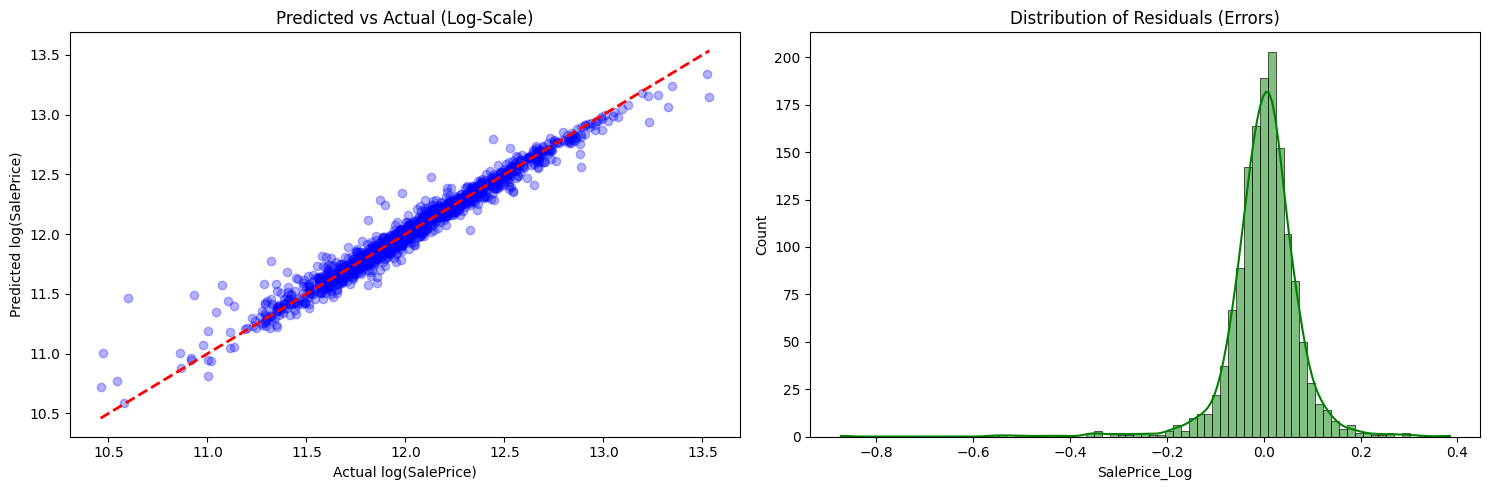

In [3]:

plt.figure(figsize=(15, 5))

# A. Predicted vs Actual
plt.subplot(1, 2, 1)
plt.scatter(y_true_log, preds_log, alpha=0.3, color='blue')
plt.plot([y_true_log.min(), y_true_log.max()], [y_true_log.min(), y_true_log.max()], 'r--', lw=2)
plt.xlabel('Actual log(SalePrice)')
plt.ylabel('Predicted log(SalePrice)')
plt.title('Predicted vs Actual (Log-Scale)')

# B. Residual Distribution
residuals = y_true_log - preds_log
plt.subplot(1, 2, 2)
sns.histplot(residuals, kde=True, color='green')
plt.title('Distribution of Residuals (Errors)')

plt.tight_layout()
plt.savefig('../charts/valuation_diagnostics.png')
plt.show()
